# Marketing A/B Testing & Conversion Analysis

## Business Problem

This project analyzes whether showing users an advertisement leads to more conversions than showing them a public service announcement (PSA).

Users are divided into two groups:

- **Ad group (`ad`)** - Users who were shown the advertising campaign.
- **PSA group (`psa`)** - Users who were shown a public service announcement instead.

The goal is to compare the conversion rates of both groups, measure the impact of the advertising campaign, and determine whether the difference is statistically significant.

### Key business questions

1. Does the advertising campaign significantly increase the conversion rate?
2. How much higher or lower is the conversion rate in the ad group?
3. What is the 95% confidence interval for the difference in conversion rates?
4. How does ad exposure vary across users, days, and hours?
5. What conclusions can we draw from the results, and what limitations should we consider before making campaign       recommendations?
   

## 1. Experiment Setup & Hypothesis Testing

### Experiment groups

| Group | Role |

| `ad` | Treatment - advertising campaign \
| `psa` | Control - public service announcement |

### Hypotheses

We compare the population conversion rates of the two groups.

- **H₀ (null hypothesis):** Both groups have the same conversion rate `p_ad = p_psa`
- **H₁ (alternative hypothesis):** The ad group has a higher conversion rate `p_ad > p_psa`

We use a one-sided two-proportion z-test with the following settings:

- Significance level: **α = 0.05**
- Test statistic: **z-score**
- Decision rule: reject H₀ when **p-value < 0.05**

### Why a two-proportion z-test?

Conversion is binary (`True` / `False`), so each user either converted or did not convert. We are comparing the conversion proportions of **two independent groups**, which makes a two-proportion z-test appropriate.


In [1]:
# Import libraries used throughout the analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from statsmodels.stats.proportion import proportions_ztest

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load the Provided Dataset

The analysis uses the **CSV file supplied with this project**. No Kaggle API or external download is required.

For reproducibility, the notebook expects `marketing_AB.csv` to be in the same folder as the notebook.


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("faviovaz/marketing-ab-testing")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\user\.cache\kagglehub\datasets\faviovaz\marketing-ab-testing\versions\1


In [3]:
import os

# Check files in the downloaded path
print("Dataset path:", path)
print("Files in directory:", os.listdir(path))


Dataset path: C:\Users\user\.cache\kagglehub\datasets\faviovaz\marketing-ab-testing\versions\1
Files in directory: ['marketing_AB.csv']


In [4]:
# Correct path to the dataset file
file_path = "C:/Users/user/.cache/kagglehub/datasets/faviovaz/marketing-ab-testing/versions/1/marketing_AB.csv"

# Load the dataset
df = pd.read_csv(file_path)

display(df.head())

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [5]:
# Check column details

print("Column information:")
display(pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isna().sum().values,
    "Unique Values": [df[col].nunique() for col in df.columns]
}))

print("\nDuplicate user IDs:", df["user id"].duplicated().sum())


Column information:


,Column,Data Type,Missing Values,Unique Values
0,Unnamed: 0,int64,0,588101
1,user id,int64,0,588101
2,test group,object,0,2
3,converted,bool,0,2
4,total ads,int64,0,807
5,most ads day,object,0,7
6,most ads hour,int64,0,24



Duplicate user IDs: 0


## 3. Data Cleaning

Removed the unnecessary Unnamed: 0 column. Retained the remaining columns for A/B testing and campaign analysis, including conversion rates, ad exposure, and exposure patterns by day and hour

In [6]:
df = df.drop(columns=["Unnamed: 0"])

# Standardize the conversion field as Boolean
df["converted"] = df["converted"].astype(bool)

print("Cleaned shape:", df.shape)
display(df.head())


Cleaned shape: (588101, 6)


,user id,test group,converted,total ads,most ads day,most ads hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14


## 4. Data Quality & Experiment Sanity Checks

Before hypothesis testing, we check for duplicate users, missing values, valid experiment groups, binary conversion values, and non-negative ad exposure to ensure the data is ready for analysis.

In [7]:
# Data quality checks

quality_checks = pd.DataFrame({
    "Check": [
        "Missing values",
        "Duplicate user IDs",
        "Unexpected test groups",
        "Non-binary conversion values",
        "Negative ad counts"
    ],
    "Result": [
        int(df.isna().sum().sum()),
        int(df["user id"].duplicated().sum()),
        sorted(set(df["test group"].unique()) - {"ad", "psa"}),
        sorted(set(df["converted"].unique()) - {True, False}),
        int((df["total ads"] < 0).sum())
    ]
})

display(quality_checks)

print("\nGroup counts:")
display(df["test group"].value_counts().rename("users").to_frame())

print("\nConversion counts:")
display(pd.crosstab(df["test group"], df["converted"]))


,Check,Result
0,Missing values,0
1,Duplicate user IDs,0
2,Unexpected test groups,[]
3,Non-binary conversion values,[]
4,Negative ad counts,0



Group counts:


,users
test group,
ad,564577
psa,23524



Conversion counts:


converted,False,True
test group,,
ad,550154,14423
psa,23104,420


## Create a Balanced Analytical Sample

The original dataset had a highly unequal group size: 564,577 Ad users vs 23,524 PSA users. To make the comparison more balanced, \
I randomly selected 23,524 Ad users to match the PSA group and combined both groups into a new analytical dataset.

In [8]:
psa = df[df["test group"] == "psa"]
ad = df[df["test group"] == "ad"].sample(n=len(psa), random_state=42)

df_balanced = (pd.concat([psa, ad]).sample(frac=1, random_state=42).reset_index(drop=True))

print("Balanced dataset shape:", df_balanced.shape)

display(df_balanced["test group"].value_counts())

Balanced dataset shape: (47048, 6)


test group
ad     23524
psa    23524
Name: count, dtype: int64

## 5. Conversion Rate Comparison: Ad vs PSA

Calculate the conversion rate for the ad and PSA groups to compare their performance.

### Formula

**Conversion Rate = Conversions / Total Users**


In [9]:
# Calculate group-level conversion metrics

group_summary = (
    df_balanced.groupby("test group")["converted"]
      .agg(users="count", conversions="sum", conversion_rate="mean")
      .reindex(["psa", "ad"])
)

group_summary["conversion_rate_pct"] = group_summary["conversion_rate"] * 100

display(group_summary[["users", "conversions", "conversion_rate_pct"]])


,users,conversions,conversion_rate_pct
test group,,,
psa,23524,420,1.7854
ad,23524,637,2.7079


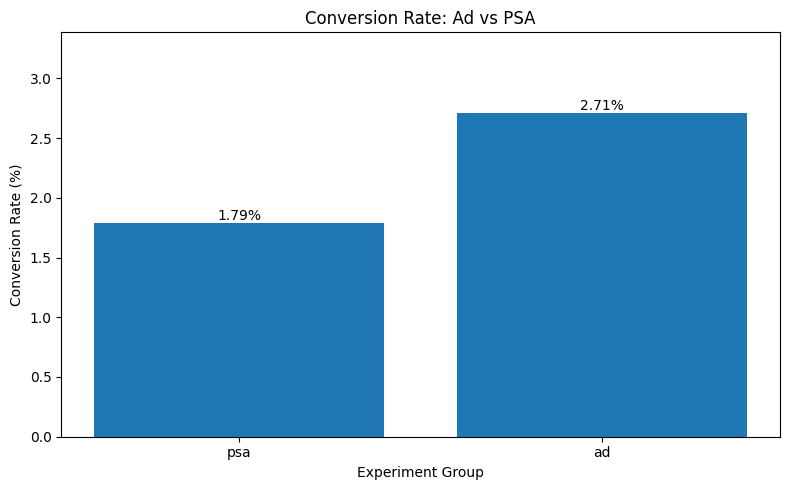

In [10]:
# Visual comparison of conversion rates

plot_data = group_summary.reset_index()

plt.figure(figsize=(8, 5))
bars = plt.bar(plot_data["test group"], plot_data["conversion_rate_pct"])

plt.title("Conversion Rate: Ad vs PSA")
plt.xlabel("Experiment Group")
plt.ylabel("Conversion Rate (%)")

plt.bar_label(bars, fmt="%.2f%%")

plt.ylim(0, max(plot_data["conversion_rate_pct"]) * 1.25)
plt.tight_layout()
plt.show()


## 6. A/B Test - Two-Proportion Z-Test

### Hypotheses

- **H₀:** The ad and PSA groups have equal conversion rates.
- **H₁:** The ad group has a higher conversion rate then the PSA group.

The one-sided two-proportion z-test uses a pooled conversion rate under H₀ to calculate the standard error.
### Interpretation

- A small p-value provides evidence that the ad group's conversion rate is higher than the PSA group's.
- Statistical significance does not measure the size or business impact of the improvement, so effect size and confidence intervals are examined next.


In [11]:
# Two-proportion z-test

ad_conversions = int(group_summary.loc["ad", "conversions"])
psa_conversions = int(group_summary.loc["psa", "conversions"])

ad_users = int(group_summary.loc["ad", "users"])
psa_users = int(group_summary.loc["psa", "users"])

counts = np.array([ad_conversions, psa_conversions])
sample_sizes = np.array([ad_users, psa_users])

z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=sample_sizes,
    alternative="larger"
)

alpha = 0.05

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.3e}")
print(f"Significance level (alpha): {alpha:.2f}")

if p_value < alpha:
    print("\nDecision: Reject H0.")
    print("Conclusion: There is statistically significant evidence that the Ad group's conversion rate is higher than the PSA group.")
else:
    print("\nDecision: Fail to reject H0.")
    print("Conclusion: There is insufficient evidence to conclude that the Ad group's conversion rate is higher than the PSA group.")


Z-statistic: 6.7508
P-value: 7.351e-12
Significance level (alpha): 0.05

Decision: Reject H0.
Conclusion: There is statistically significant evidence that the Ad group's conversion rate is higher than the PSA group.


## 7. Effect Size - Absolute Uplift and Relative Lift

### Absolute uplift

**Absolute Uplift = Conversion Rate (Ad) - Conversion Rate (PSA)**

This tells us the increase in conversion measured in **percentage points**.

### Relative lift

**Relative Lift = (Ad Rate - PSA Rate) / PSA Rate × 100**

This tells us how much higher the ad conversion rate is relative to the PSA baseline.


In [12]:
# Calculate absolute uplift and relative lift

ad_rate = group_summary.loc["ad", "conversion_rate"]
psa_rate = group_summary.loc["psa", "conversion_rate"]

absolute_uplift = ad_rate - psa_rate
relative_lift = (absolute_uplift / psa_rate) * 100

print(f"Ad conversion rate:        {ad_rate * 100:.4f}%")
print(f"PSA conversion rate:       {psa_rate * 100:.4f}%")
print(f"Absolute uplift:           {absolute_uplift * 100:.4f} percentage points")
print(f"Relative lift:             {relative_lift:.2f}%")


Ad conversion rate:        2.7079%
PSA conversion rate:       1.7854%
Absolute uplift:           0.9225 percentage points
Relative lift:             51.67%


## 8. 95% Confidence Interval for the Conversion-Rate Difference

95% confidence interval estimates a plausible range for the true difference between the two groups' conversion rates.

We estimate:

**p_ad - p_psa**

We use the unpooled standard error because each group's conversion rate is estimated separately.

### Interpretation

- If the 95% confidence interval is entirely above zero, it supports the conclusion that the ad group has a higher conversion rate than the PSA group.

- The interval shows the uncertainty around the estimated improvement, while the p-value helps assess statistical evidence.


In [13]:
# 95% one-sided confidence interval for Ad > PSA

z_critical = norm.ppf(1 - alpha)

se_difference = np.sqrt(
    (ad_rate * (1 - ad_rate) / ad_users)
    + (psa_rate * (1 - psa_rate) / psa_users)
)

ci_lower = absolute_uplift - z_critical * se_difference

print(f"Estimated difference (Ad - PSA): {absolute_uplift * 100:.4f} percentage points")
print(f"95% one-sided lower bound:       {ci_lower * 100:.4f} percentage points")

Estimated difference (Ad - PSA): 0.9225 percentage points
95% one-sided lower bound:       0.6978 percentage points


## 9. Summary of A/B Test Results

The table below summarizes the key results of the experiment, including conversion rates, absolute uplift, relative lift, the z-statistic, p-value, and confidence interval.

These results help us determine whether the ad group performed better than the PSA group. 

**Note:** The experiment result supports a difference in conversion rates. It does not, by itself, justify a specific revenue figure because the dataset does not contain purchase value or revenue per conversion. Therefore, no artificial revenue estimate is included in this project.


In [14]:
# Final statistical results table

results = pd.DataFrame({
    "Metric": [
        "Ad conversion rate",
        "PSA conversion rate",
        "Absolute uplift",
        "Relative lift",
        "Z-statistic",
        "P-value",
        "95% CI - lower bound",
        "Decision"
    ],
    "Result": [
        f"{ad_rate * 100:.4f}%",
        f"{psa_rate * 100:.4f}%",
        f"{absolute_uplift * 100:.4f} percentage points",
        f"{relative_lift:.2f}%",
        f"{z_stat:.4f}",
        f"{p_value:.10f}",
        f"{ci_lower * 100:.4f} percentage points",
        "Reject H0" if p_value < alpha else "Fail to reject H0"
    ]
})

display(results)


,Metric,Result
0,Ad conversion rate,2.7079%
1,PSA conversion rate,1.7854%
2,Absolute uplift,0.9225 percentage points
3,Relative lift,51.67%
4,Z-statistic,6.7508
5,P-value,0.0000000000
6,95% CI - lower bound,0.6978 percentage points
7,Decision,Reject H0


## 10. Exploratory Analysis - Ad Exposure Patterns

We examine:

- number of ads seen,
- day with the highest ad exposure,
- hour with the highest ad exposure,
- conversion patterns across exposure levels.

### Why separate this section?

The randomized treatment comparison answers whether the **ad treatment** is associated with higher conversion than the PSA control.

This analysis shows how many ads users in each group saw. However, seeing more ads alongside higher conversions does not necessarily mean that more ads caused the increase in conversions. Other factors, such as user engagement, may also influence conversions.


In [15]:
df.head()

,user id,test group,converted,total ads,most ads day,most ads hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14


In [16]:
# Compare average ad exposure between the two experiment groups

exposure_summary = (
    df.groupby("test group")["total ads"]
      .agg(["count", "mean", "median", "min", "max"])
      .reindex(["psa", "ad"])
)

display(exposure_summary)


,count,mean,median,min,max
test group,,,,,
psa,23524,24.7611,12.0000,1,907
ad,564577,24.8234,13.0000,1,2065


C:\Users\user\AppData\Local\Temp\ipykernel_15196\1431599804.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


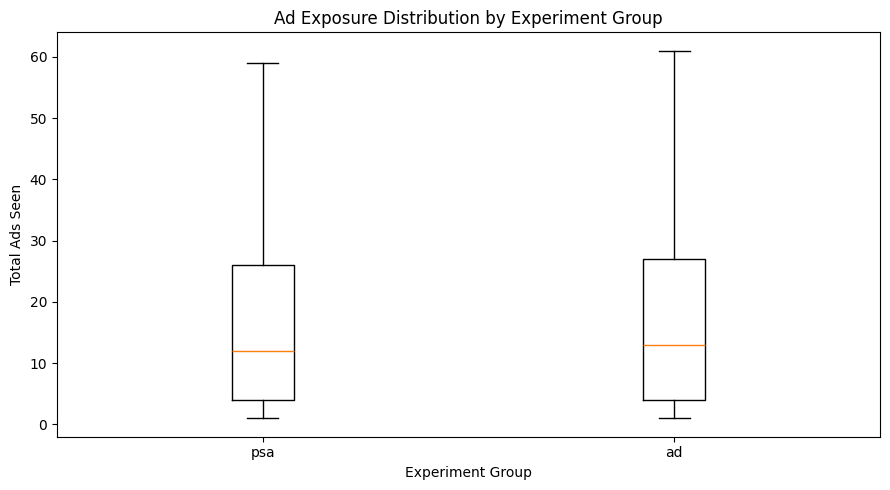

In [17]:
# Distribution of ad exposure by experiment group

psa_ads = df.loc[df["test group"] == "psa", "total ads"]
ad_ads = df.loc[df["test group"] == "ad", "total ads"]

plt.figure(figsize=(9, 5))
plt.boxplot(
    [psa_ads, ad_ads],
    labels=["psa", "ad"],
    showfliers=False
)

plt.title("Ad Exposure Distribution by Experiment Group")
plt.xlabel("Experiment Group")
plt.ylabel("Total Ads Seen")
plt.tight_layout()
plt.show()


In [18]:
df.head()

,user id,test group,converted,total ads,most ads day,most ads hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14


,Exposure Share (%)
most ads day,
Monday,14.8058
Tuesday,13.1744
Wednesday,13.7575
Thursday,14.1102
Friday,15.7470
Saturday,13.8854
Sunday,14.5198


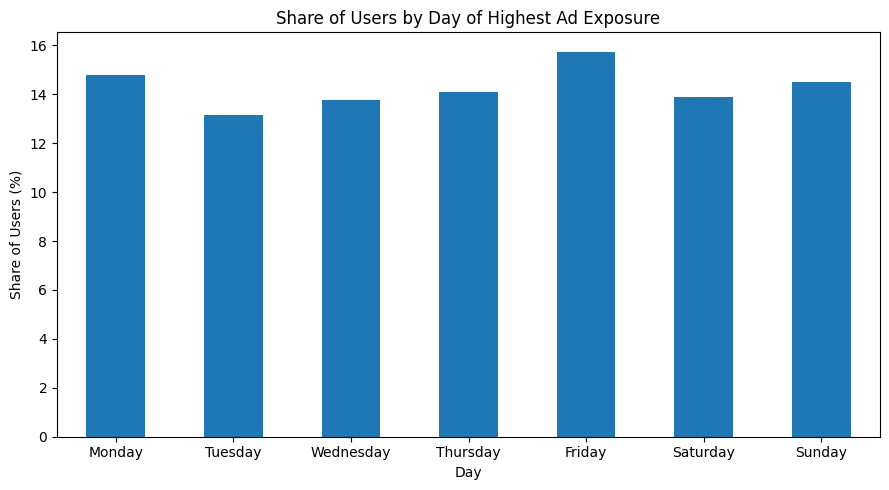

In [19]:
# Day-level exposure share

day_exposure = (
    df["most ads day"]
      .value_counts(normalize=True)
      .mul(100)
      .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
)

display(day_exposure.rename("Exposure Share (%)").to_frame())

plt.figure(figsize=(9, 5))
ax = day_exposure.plot(kind="bar")
plt.title("Share of Users by Day of Highest Ad Exposure")
plt.xlabel("Day")
plt.ylabel("Share of Users (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,Exposure Share (%)
most ads hour,
0,0.9413
1,0.8165
2,0.9068
3,0.4555
4,0.1228
5,0.1301
6,0.3516
7,1.0891
8,2.9973


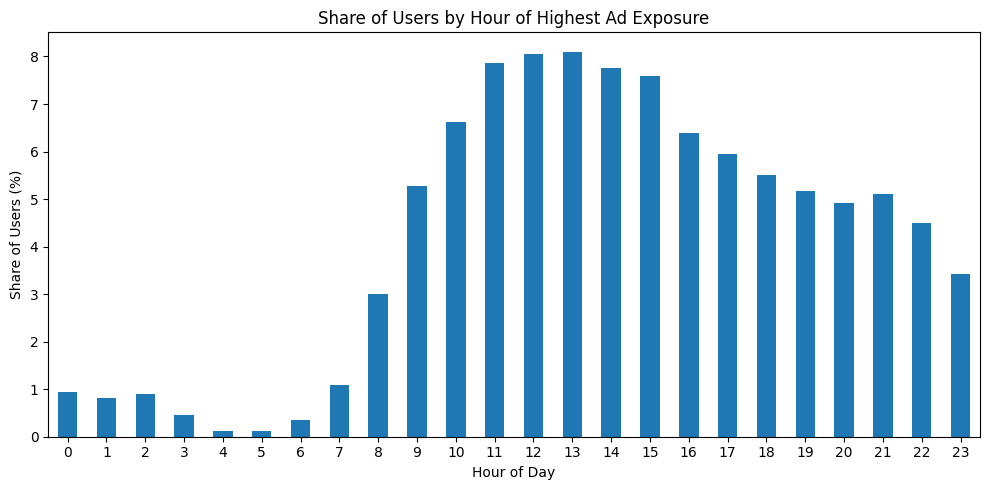

In [20]:
# Hour-level exposure share

hour_exposure = (
    df["most ads hour"]
      .value_counts(normalize=True)
      .sort_index()
      .mul(100)
)

display(hour_exposure.rename("Exposure Share (%)").to_frame())

plt.figure(figsize=(10, 5))
hour_exposure.plot(kind="bar")
plt.title("Share of Users by Hour of Highest Ad Exposure")
plt.xlabel("Hour of Day")
plt.ylabel("Share of Users (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 11. Conversion Pattern by Day - Exploratory Only

Comparing daily conversion rates helps identify patterns that may be useful for future experiments.

However, differences across days do not prove that the day itself affects conversions, as other factors may also influence the results. 
This analysis is exploratory, not proof of cause.


In [21]:
df.head()

,user id,test group,converted,total ads,most ads day,most ads hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14


,Ad Group Conversion Rate (%)
most ads day,
Monday,3.3241
Tuesday,3.0440
Wednesday,2.5356
Thursday,2.1637
Friday,2.2465
Saturday,2.1307
Sunday,2.4620


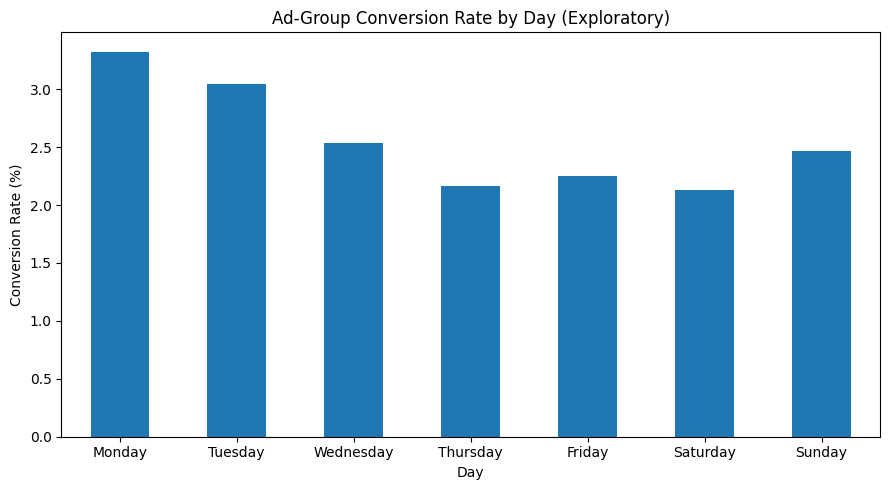

In [22]:
# Conversion rate by day within the AD treatment group

ad_day_conversion = (
    df[df["test group"] == "ad"]
      .groupby("most ads day")["converted"]
      .mean()
      .mul(100)
      .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
)

display(ad_day_conversion.rename("Ad Group Conversion Rate (%)").to_frame())

plt.figure(figsize=(9, 5))
ax = ad_day_conversion.plot(kind="bar")
plt.title("Ad-Group Conversion Rate by Day (Exploratory)")
plt.xlabel("Day")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,Ad Group Conversion Rate (%)
most ads hour,
16,3.0893
20,3.0274
15,2.9845
21,2.9175
14,2.8575
17,2.8537
18,2.7470
19,2.6809
22,2.6455


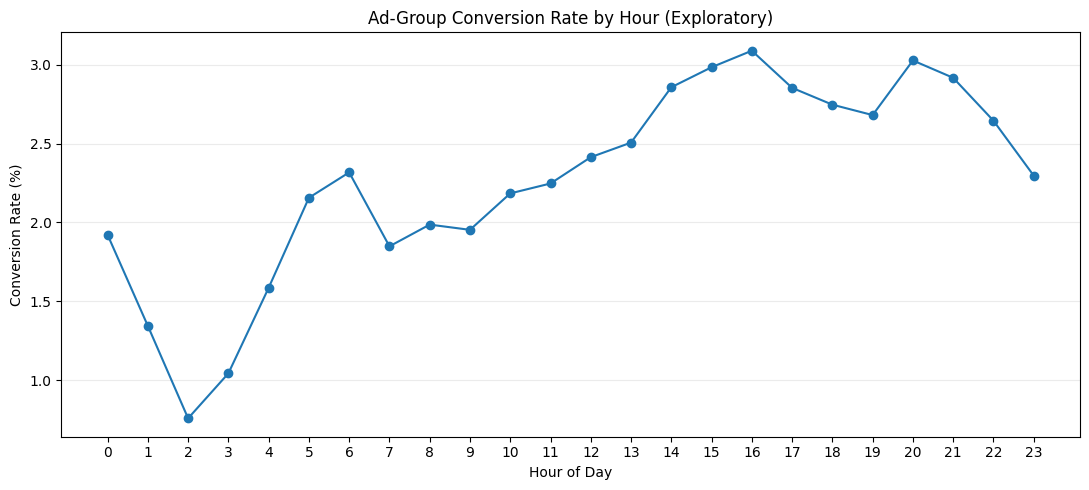

In [23]:
# Conversion rate by hour within the AD treatment group

ad_hour_conversion = (
    df[df["test group"] == "ad"]
      .groupby("most ads hour")["converted"]
      .mean()
      .mul(100)
      .sort_index()
)

display(ad_hour_conversion.to_frame("Ad Group Conversion Rate (%)").sort_values(
    "Ad Group Conversion Rate (%)", ascending=False
).head(10))

plt.figure(figsize=(11, 5))
ad_hour_conversion.plot(kind="line", marker="o")
plt.title("Ad-Group Conversion Rate by Hour (Exploratory)")
plt.xlabel("Hour of Day")
plt.ylabel("Conversion Rate (%)")
plt.xticks(range(0, 24))
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 12. Relationship Between Ads Seen and Conversion

We check whether users who see more ads also have higher conversion rates.

### Important limitation

This shows a relationship, not proof of cause. For example, more engaged users may see more ads and be more likely to convert. Therefore, seeing more ads does not necessarily mean that showing more ads will increase conversions.


In [24]:
df.head()

,user id,test group,converted,total ads,most ads day,most ads hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14


In [25]:
df.dtypes

user id           int64
test group       object
converted          bool
total ads         int64
most ads day     object
most ads hour     int64
dtype: object

In [26]:
# Correlation between numeric variables

correlation = df[["total ads", "most ads hour", "converted"]].astype(int).corr()

display(correlation)

print(
    f"Correlation between total ads and conversion: "
    f"{correlation.loc['total ads', 'converted']:.4f}"
)


,total ads,most ads hour,converted
total ads,1.0000,-0.0108,0.2174
most ads hour,-0.0108,1.0000,0.0197
converted,0.2174,0.0197,1.0000


Correlation between total ads and conversion: 0.2174


,Conversion Rate (%)
exposure_quartile,
Q1 - Lowest,0.2343
Q2,0.5180
Q3,1.1887
Q4 - Highest,8.2387


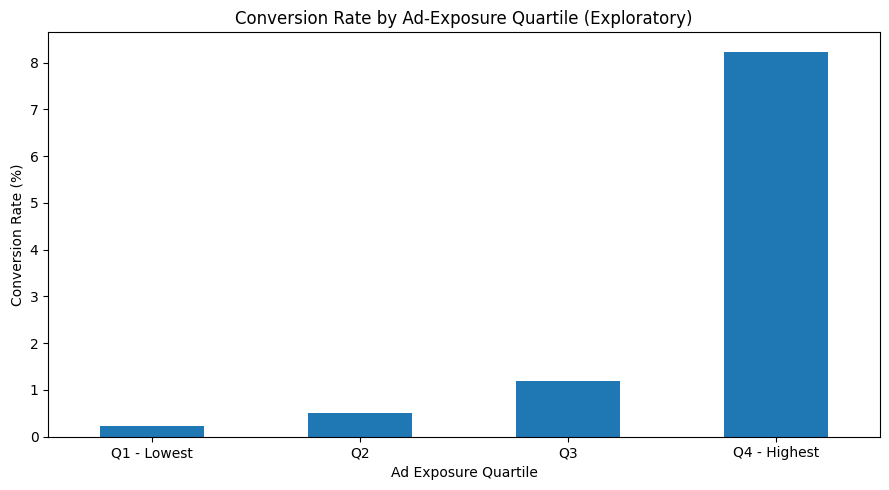

In [27]:
# Compare conversion rate across ad-exposure quartiles

df["exposure_quartile"] = pd.qcut(
    df["total ads"],
    q=4,
    labels=["Q1 - Lowest", "Q2", "Q3", "Q4 - Highest"],
    duplicates="drop"
)

exposure_conversion = (
    df.groupby("exposure_quartile", observed=False)["converted"]
      .mean()
      .mul(100)
)

display(exposure_conversion.rename("Conversion Rate (%)").to_frame())

plt.figure(figsize=(9, 5))
ax = exposure_conversion.plot(kind="bar")
plt.title("Conversion Rate by Ad-Exposure Quartile (Exploratory)")
plt.xlabel("Ad Exposure Quartile")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 13. Business Interpretation

### What the A/B test tells us
The ad group had a higher conversion rate than the PSA group. The two-proportion z-test showed strong statistical evidence that the ad campaign performed better.

The **51.67% relative lift** shows the percentage improvement compared with the PSA group, while the **absolute uplift** shows the difference in conversion rates in percentage points.

### What the exploratory analysis tells us

- Friday has the highest share of users whose highest ad exposure occurred on that day.
- Monday and Tuesday had higher observed conversion rates than several other days in the ad group.
- Conversion rates varied by hour.
- Users who saw more ads also tended to have higher conversion rates.

### What we should NOT claim

- We should not say Friday is automatically the best day to spend more budget simply because Friday has the highest exposure.
- We should not say that more ads **cause** higher conversion based on correlation.
- Revenue impact cannot be calculated because the dataset does not include revenue or order values.

## 14. Recommendations

### 1. Continue evaluating the advertising treatment

The A/B test provides strong statistical evidence that the ad group outperformed the PSA control on conversion.

### 2. Report both types of improvement

Report both:

- **absolute uplift:** percentage-point improvement
- **relative lift:** improvement relative to the PSA baseline

This prevents a statistically significant result from being communicated without business context.

### 3. Treat day/hour findings as hypotheses for future experiments

Use the observed patterns to plan future controlled experiments before changing the campaign schedule or budget.

### 4. Test ad frequency

Users who saw more ads also tended to convert more. Run a controlled experiment to check whether showing 
additional ads actually increases conversions.

### 5. Include revenue data in future analysis

Collect revenue or order-value data to measure whether the campaign increases revenue, not just conversions.


## 15. Final Conclusion

### Statistical conclusion

The ad group had a conversion rate of approximately **2.71%**, compared with **1.79%** for the PSA group.

The two-proportion z-test showed a statistically significant difference **(p < 0.05)**, providing strong evidence that the ad group had a higher conversion rate.

The ad group achieved approximately **51.67%** relative lift compared with the PSA group.

### Analyst conclusion

The results suggest that the advertising campaign performed better than the PSA control in terms of conversion rate.

The analysis of ad views by day, hour, and frequency revealed useful patterns for future testing. However, these patterns do not prove that showing more ads or changing the timing will increase conversions.
